# RetailRocket — Exploratory Data Analysis

**Purpose.** Researchers characterize the dataset before defining splits,
implicit/explicit relevance, or models. They use validated Parquet outputs
and compute scalable aggregates without loading all event records in pandas.

**Research hypotheses**
- H1: Views dominate the event mix relative to carts and transactions.
- H2: User histories are highly sparse, creating practical cold-start constraints.
- H3: Activity and event composition change across calendar months.

**Scope.** They treat these as descriptive hypotheses. No predictive or
causal conclusion is established by the EDA alone.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from recsys.eda import (
    load_eda_dataset, overview, compare_datasets,
    activity_summary, activity_bins,
    event_distribution, rating_distribution,
    monthly_events, top_items, item_concentration,
    cold_start_snapshot,
)

from recsys.eda_plots import (
    plot_activity_bins, plot_event_types, plot_ratings,
    plot_monthly_events, plot_cold_start,
)

# Researchers locate the project root whether the kernel starts
# from the repository root or from the notebooks/ directory.
ROOT = Path.cwd()

if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent

if not (ROOT / "data" / "processed").is_dir():
    raise FileNotFoundError(
        "Expected data/processed in the project root"
    )

DATASET = "retailrocket"

ds = load_eda_dataset(
    DATASET,
    ROOT / "data" / "processed",
)

FIGURES = (
    ROOT / "reports" / "figures" / DATASET
)

print(
    f"Dataset: {ds.name}; "
    f"validation: {ds.validation['valid']}"
)


Dataset: retailrocket; validation: True


## 1. Provenance and data quality

Researchers review the validated data population, observation
window, and warnings before interpreting aggregate patterns.

They do not equate validation success with the absence of
selection bias.


In [2]:
display(overview(ds))

display(Markdown(
    "**Validation notes:** "
    + "; ".join(ds.validation.get("warnings", []))
))

display(
    compare_datasets(
        ROOT / "data" / "processed"
    )
)


,metric,value
0,Events,2756101
1,Users,1407580
2,Items,235061
3,Unique user-item pairs,2145179
4,Repeated user-item events,610922
5,Potential duplicate observations,460
6,Observed matrix sparsity,0.999994
7,Earliest event (UTC),2015-05-03T03:00:04.384000+00:00
8,Latest event (UTC),2015-09-18T02:59:47.788000+00:00


**Validation notes:** Views, carts, and transactions remain separate behavioral events.; Item-property snapshots are not joined: attributes require as-of-time joins.; 460 repeated event observations detected; none removed.

,dataset,events,users,items,sparsity,first_event,last_event
0,amazon-video-games,814586,94762,25612,0.999664,1999-10-22T21:43:15+00:00,2023-09-02T18:14:28.630000+00:00
1,movielens-1m,1000209,6040,3706,0.955316,2000-04-25T23:05:32+00:00,2003-02-28T17:49:50+00:00
2,retailrocket,2756101,1407580,235061,0.999994,2015-05-03T03:00:04.384000+00:00,2015-09-18T02:59:47.788000+00:00


## 2. Observed feedback

Researchers examine the event mix before specifying targets.

They preserve the distinction between explicit rating
values and implicit behavior.


,event_type,events,percent
0,view,2664312,96.669607
1,addtocart,69332,2.515583
2,transaction,22457,0.814810


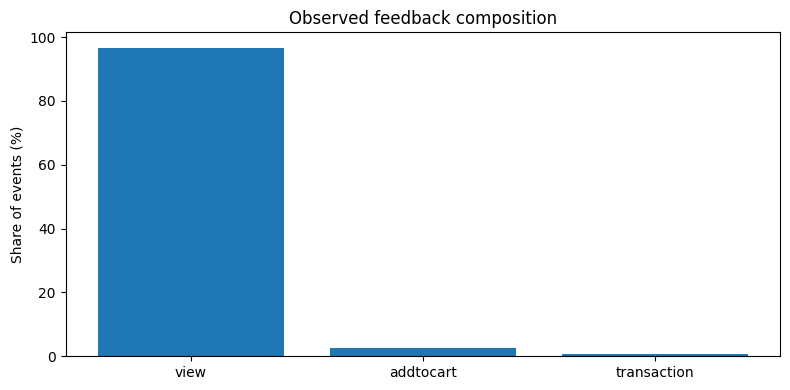

In [3]:
feedback = event_distribution(ds)

display(feedback)

fig = plot_event_types(
    feedback,
    FIGURES / "feedback_mix.png",
)

display(fig)
plt.close(fig)

ratings = rating_distribution(ds)

if not ratings.empty:

    display(ratings)

    fig = plot_ratings(
        ratings,
        FIGURES / "ratings.png",
    )

    display(fig)
    plt.close(fig)


## 3. User activity and item popularity

Researchers examine approximate quantiles and log-binned
interaction frequencies.

They avoid loading per-user frequency tables into
notebook memory.


,entities,min_events,mean_events,approx_median,approx_p95,approx_p99,max_events,singletons,entity
0,1407580,1,1.958042,1,5,13,7757,1001560.0,users


,entities,min_events,mean_events,approx_median,approx_p95,approx_p99,max_events,singletons,entity
0,235061,1,11.725046,3,48,144,3412,73609.0,items


,bin_power,entities,events
0,0,1001560,1001560.0
1,1,285604,650820.0
2,2,85423,421461.0
3,3,25061,257166.0
4,4,7101,148864.0
5,5,2015,85550.0
6,6,515,43933.0
7,7,150,26104.0
8,8,77,28087.0
9,9,45,32389.0


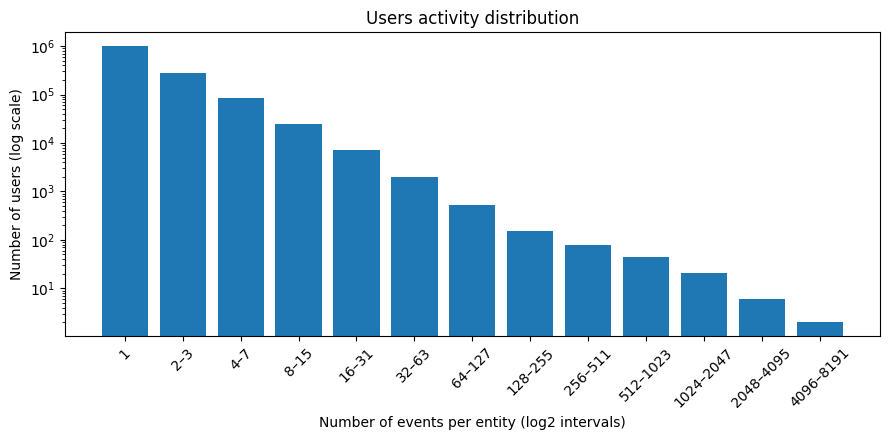

,bin_power,entities,events
0,0,73609,73609.0
1,1,55898,132865.0
2,2,40245,208237.0
3,3,27976,302019.0
4,4,18423,404791.0
5,5,10813,475117.0
6,6,5254,460379.0
7,7,2092,364096.0
8,8,591,201568.0
9,9,127,85070.0


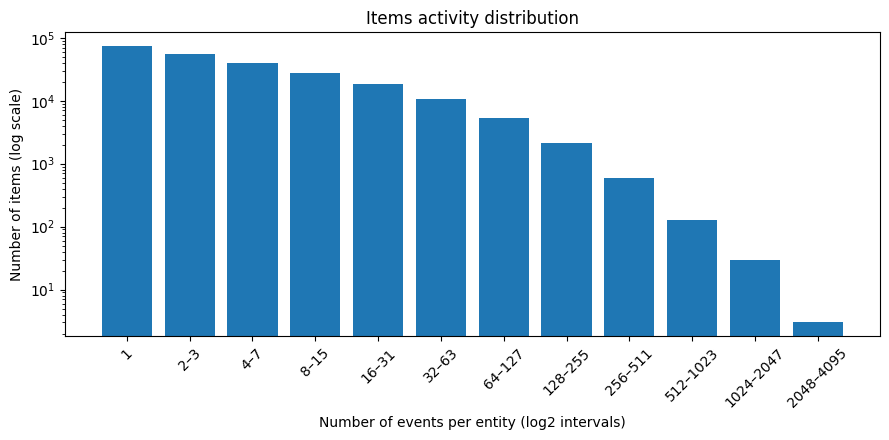

In [4]:
user_stats = activity_summary(
    ds,
    "user_id",
)

item_stats = activity_summary(
    ds,
    "item_id",
)

display(
    user_stats.assign(entity="users")
)

display(
    item_stats.assign(entity="items")
)

for field, title in (
    ("user_id", "users"),
    ("item_id", "items"),
):

    bins = activity_bins(
        ds,
        field,
    )

    display(bins)

    fig = plot_activity_bins(
        bins,
        title,
        FIGURES / f"{title}_activity.png",
    )

    display(fig)
    plt.close(fig)


## 4. Popularity concentration

Researchers quantify how much activity belongs to the
most active 1% and 10% of items.

They do not interpret event counts as relevance.


In [5]:
concentration = item_concentration(ds)

display(concentration)

display(
    top_items(ds, limit=15)
)


,n_items,total_events,top_1pct_event_share,top_10pct_event_share
0,235061,2756101.0,0.229546,0.640295


,item_id,events,distinct_users
0,187946,3412,2912
1,461686,2978,1393
2,5411,2334,2079
3,370653,1854,1577
4,219512,1800,1370
5,257040,1647,986
6,298009,1642,1342
7,96924,1633,1359
8,309778,1628,1055
9,384302,1608,1154


## 5. Temporal dynamics

Researchers inspect monthly interaction volumes in UTC.

They distinguish observed activity changes from potential
changes in data collection coverage.


,month,event_type,events,active_users,active_items
0,2015-05-01 00:00:00+00:00,addtocart,14369,7949,7938
1,2015-05-01 00:00:00+00:00,transaction,4611,2546,3376
2,2015-05-01 00:00:00+00:00,view,571672,306915,114653
3,2015-06-01 00:00:00+00:00,addtocart,15095,8595,8144
4,2015-06-01 00:00:00+00:00,transaction,5043,2728,3589
5,2015-06-01 00:00:00+00:00,view,590255,313218,117153
6,2015-07-01 00:00:00+00:00,addtocart,17362,9434,8937
7,2015-07-01 00:00:00+00:00,transaction,5802,2971,4024
8,2015-07-01 00:00:00+00:00,view,674820,376336,126474
9,2015-08-01 00:00:00+00:00,addtocart,14825,8315,7920


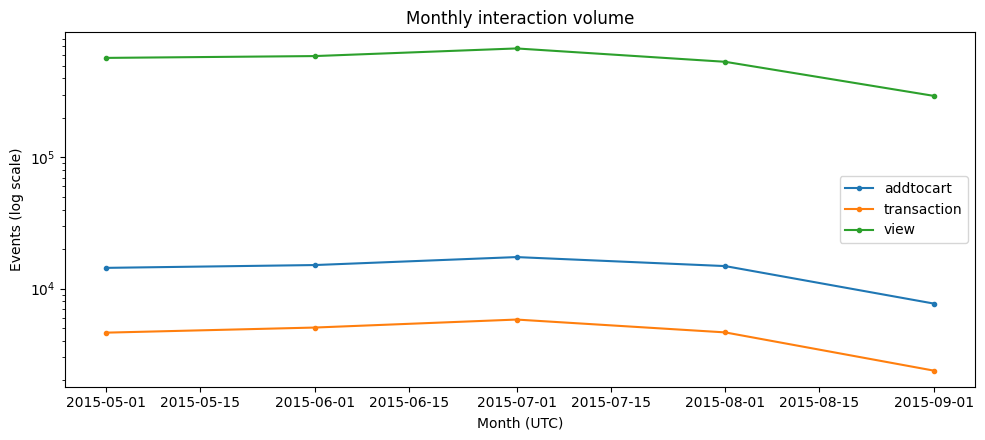

In [6]:
monthly = monthly_events(ds)

display(
    monthly.head(12)
)

fig = plot_monthly_events(
    monthly,
    FIGURES / "monthly_volume.png",
    log_scale=True,
)

display(fig)
plt.close(fig)


## 6. Cold-start exposure under a global time cutoff

Researchers use the timestamp at approximately the 80th
percentile of event times as a diagnostic boundary.

They classify later events by whether their users
and items had appeared in the historical window.

The resulting groups are disjoint:

- `warm`
- `new_user`
- `new_item`
- `new_user_and_item`

**Caution:** This is not the final train/validation/test
protocol. The modeling split will be defined during
the later splitting stage.


Diagnostic cutoff (UTC): 2015-08-18T04:23:31.966000080+00:00


,event_type,segment,events,percent_within_type
0,addtocart,new_item,216,1.505541
1,addtocart,new_user,10901,75.981041
2,addtocart,new_user_and_item,671,4.676936
3,addtocart,warm,2559,17.836481
4,transaction,new_item,64,1.393425
5,transaction,new_user,3082,67.102112
6,transaction,new_user_and_item,170,3.701285
7,transaction,warm,1277,27.803179
8,view,new_item,6229,1.170249
9,view,new_user,425690,79.974825


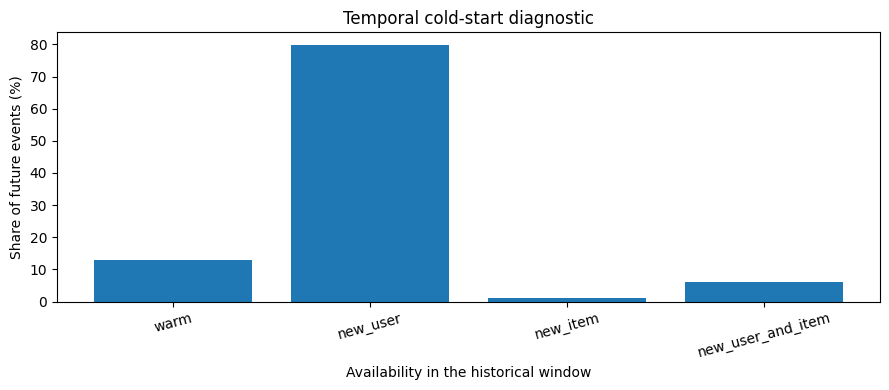

In [7]:
cutoff, cold = cold_start_snapshot(
    ds,
    history_fraction=0.8,
)

print(
    f"Diagnostic cutoff (UTC): {cutoff.isoformat()}"
)

display(cold)

fig = plot_cold_start(
    cold,
    FIGURES / "cold_start.png",
)

display(fig)
plt.close(fig)


## 7. Scientific interpretation and modeling implications

Researchers should preserve event strength differences and avoid treating all views as conversions. Item-property snapshots remain unjoined until as-of-time feature engineering is implemented.

Researchers summarize quantitative evidence before choosing
thresholds, sampling methods, features, or evaluation protocols.

They interpret these diagnostics as observational descriptions
rather than predictive performance estimates.


In [8]:
item_share = float(
    concentration.loc[
        0,
        "top_1pct_event_share",
    ]
)

sparse = float(
    ds.validation["statistics"]["interaction_sparsity"]
)

new_events = cold.loc[
    cold["segment"] != "warm",
    "events",
].sum()

all_future = cold["events"].sum()

cold_pct = (
    100.0 * new_events / all_future
)

display(Markdown(
    f"**Observed evidence.** The top 1% of items account for "
    f"{item_share:.1%} of events. The observed interaction matrix "
    f"has {sparse:.2%} sparsity. After the diagnostic cutoff, "
    f"{cold_pct:.1f}% of subsequent events involve at least one "
    f"previously unseen user or item."
))

# Researchers limit dataset-specific interpretations
# to quantities computed from the current artifacts.
if DATASET == "retailrocket":

    views = feedback.loc[
        feedback["event_type"] == "view",
        "percent",
    ]

    if not views.empty:

        display(Markdown(
            f"**Implicit-feedback implication.** "
            f"Views represent {float(views.iloc[0]):.1f}% "
            f"of observed events; event-strength weighting "
            f"and exposure bias require explicit study."
        ))

elif not ratings.empty:

    high = ratings.loc[
        ratings["rating"] >= 4,
        "events",
    ].sum()

    total = ratings["events"].sum()

    display(Markdown(
        f"**Explicit-feedback implication.** "
        f"Ratings of 4–5 account for "
        f"{100.0 * high / total:.1f}% of observed ratings. "
        f"They must not be interpreted as a "
        f"population-level preference rate."
    ))

if DATASET == "amazon-video-games":

    user_min = int(
        user_stats.loc[0, "min_events"]
    )

    item_min = int(
        item_stats.loc[0, "min_events"]
    )

    display(Markdown(
        f"**5-core diagnostic.** Minimum interactions "
        f"per user/item: {user_min} / {item_min}. "
        f"These counts alone cannot prove "
        f"the dataset's original sampling protocol."
    ))


**Observed evidence.** The top 1% of items account for 23.0% of events. The observed interaction matrix has 100.00% sparsity. After the diagnostic cutoff, 87.1% of subsequent events involve at least one previously unseen user or item.

**Implicit-feedback implication.** Views represent 96.7% of observed events; event-strength weighting and exposure bias require explicit study.